In [1]:
import os, glob , warnings

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from scipy import stats
from IPython.display import display
from sklearn.model_selection import TimeSeriesSplit,cross_validate,RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import median_absolute_error
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.inspection import permutation_importance

In [4]:
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
OUT = "outputs"
os.makedirs(OUT,exist_ok=True)

In [5]:
def show(name) :
    """Tidy layout, save the figure as PNG (for your portfolio) and display it ."""
    plt.tight_layout()
    plt.savefig(f"{OUT}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

**Loading The Data**

In [6]:
paths = (glob.glob("gt_full.csv") + glob.glob("/kaggle/input/**/gt_full.csv", recursive=True)
         + glob.glob("/content/**/gt_full.csv", recursive=True))
if not paths:
    raise FileNotFoundError("gt_full.csv not found. Put it next to the notebook or set DATA_PATH by hand.")
DATA_PATH = paths[0]
df_raw = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH, "| shape:", df_raw.shape)

Loaded: /kaggle/input/datasets/muniryadi/gasturbine-co-and-nox-emission-data/gt_full.csv | shape: (36733, 12)


**First Look**

In [7]:
display(df_raw.head())

,Unnamed: 0,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
0,1,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952
1,2,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377
2,3,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776
3,4,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505
4,5,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028


In [8]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36733 entries, 0 to 36732
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  36733 non-null  int64  
 1   AT          36733 non-null  float64
 2   AP          36733 non-null  float64
 3   AH          36733 non-null  float64
 4   AFDP        36733 non-null  float64
 5   GTEP        36733 non-null  float64
 6   TIT         36733 non-null  float64
 7   TAT         36733 non-null  float64
 8   TEY         36733 non-null  float64
 9   CDP         36733 non-null  float64
 10  CO          36733 non-null  float64
 11  NOX         36733 non-null  float64
dtypes: float64(11), int64(1)
memory usage: 3.4 MB


In [9]:
display(df_raw.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,36733.0,18367.000,10604.048,1.000,9184.000,18367.000,27550.000,36733.000
AT,36733.0,17.713,7.447,-6.235,11.781,17.801,23.665,37.103
AP,36733.0,1013.070,6.463,985.850,1008.800,1012.600,1017.000,1036.600
AH,36733.0,77.867,14.461,24.085,68.188,80.470,89.376,100.200
AFDP,36733.0,3.926,0.774,2.087,3.356,3.938,4.377,7.611
GTEP,36733.0,25.564,4.196,17.698,23.129,25.104,29.061,40.716
TIT,36733.0,1081.428,17.536,1000.800,1071.800,1085.900,1097.000,1100.900
TAT,36733.0,546.159,6.842,511.040,544.720,549.880,550.040,550.610
TEY,36733.0,133.506,15.619,100.020,124.450,133.730,144.080,179.500
CDP,36733.0,12.061,1.089,9.852,11.435,11.965,12.855,15.159


**Cleaning The data**

In [10]:
df = df_raw.copy()
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")]).rename(columns={"NOX":"NOx"})
NUM = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP", "CO", "NOx"]


In [11]:
rows_per_year = {2011:7411, 2012:7628 , 2013:7152, 2014:7158 , 2015:7384}
assert sum(rows_per_year.values()) == len(df), "Row counts do not match the file"
df["year"] = np.repeat(list(rows_per_year.keys()),list(rows_per_year.values()))

In [12]:
print("Missing values:", int(df.isna().sum().sum()))
dup_mask = df[NUM].duplicated(keep="first")
print("Duplicate rows (all 11 sensors identical):", int(dup_mask.sum()))
display(df[df[NUM].duplicated(keep=False)])   # they come in runs = frozen sensor readings
df = df[~dup_mask].reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Missing values: 0
Duplicate rows (all 11 sensors identical): 7


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOx,year
26398,23.156,1004.2,95.938,4.0547,24.672,1076.6,549.87,127.01,11.835,1.7056,47.352,2014
26399,23.156,1004.2,95.938,4.0547,24.672,1076.6,549.87,127.01,11.835,1.7056,47.352,2014
26400,23.156,1004.2,95.938,4.0547,24.672,1076.6,549.87,127.01,11.835,1.7056,47.352,2014
26401,23.156,1004.2,95.938,4.0547,24.672,1076.6,549.87,127.01,11.835,1.7056,47.352,2014
26402,23.156,1004.2,95.938,4.0547,24.672,1076.6,549.87,127.01,11.835,1.7056,47.352,2014
27388,26.067,1008.3,87.328,5.0703,29.984,1099.1,546.78,146.14,13.038,1.3163,52.564,2014
27389,26.067,1008.3,87.328,5.0703,29.984,1099.1,546.78,146.14,13.038,1.3163,52.564,2014
27390,26.067,1008.3,87.328,5.0703,29.984,1099.1,546.78,146.14,13.038,1.3163,52.564,2014
27391,26.067,1008.3,87.328,5.0703,29.984,1099.1,546.78,146.14,13.038,1.3163,52.564,2014


Shape after removing duplicates: (36726, 12)


In [13]:
df["pos_in_year"] = df.groupby("year").cumcount() / df.groupby("year")["AT"].transform("size")
df["year_quarter"] = pd.cut(df["pos_in_year"], [0, .25, .5, .75, 1], labels=["Q1", "Q2", "Q3", "Q4"], include_lowest=True)
display(df.pivot_table(index="year", columns="year_quarter", values="AT", aggfunc="mean", observed=False).round(1))

year_quarter,Q1,Q2,Q3,Q4
year,,,,
2011,9.5,18.7,25.4,14.8
2012,10.4,23.2,25.0,15.0
2013,10.9,17.8,25.6,16.1
2014,11.9,20.0,25.9,15.1
2015,8.9,20.4,25.9,13.6


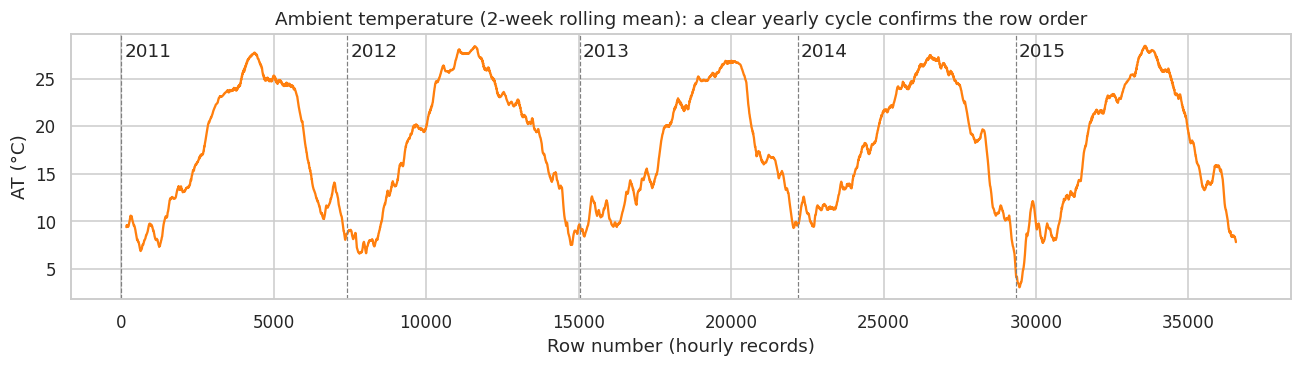

In [14]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(df["AT"].rolling(24 * 14, center=True).mean(), color="tab:orange")
for i, y in df.groupby("year").head(1)["year"].items():          # i = first row of the year, y = the year
    ax.axvline(i, color="grey", ls="--", lw=0.8); ax.text(i + 100, ax.get_ylim()[1] * 0.92, str(y))
ax.set_title("Ambient temperature (2-week rolling mean): a clear yearly cycle confirms the row order")
ax.set_xlabel("Row number (hourly records)"); ax.set_ylabel("AT (°C)")
show("01_year_check")

**CLeaning Phase 2**

In [15]:
n_above = int((df["AH"] > 100).sum())
print(f"Humidity above 100 %: {n_above} rows (max {df['AH'].max()}) -> capped at 100 (impossible physically)")
df["AH"] = df["AH"].clip(upper=100)

checks = pd.DataFrame({"min": df[NUM].min(), "max": df[NUM].max(),
                       "n_zero": (df[NUM] == 0).sum(), "n_negative": (df[NUM] < 0).sum(),
                       "n_unique": df[NUM].nunique()})
display(checks.round(3))

Humidity above 100 %: 478 rows (max 100.2) -> capped at 100 (impossible physically)


,min,max,n_zero,n_negative,n_unique
AT,-6.235,37.103,0,62,22523
AP,985.850,1036.600,0,0,791
AH,24.085,100.000,0,0,25688
AFDP,2.087,7.611,0,0,20495
GTEP,17.698,40.716,0,0,12967
TIT,1000.800,1100.900,0,0,799
TAT,511.040,550.610,0,0,2769
TEY,100.020,179.500,0,0,6236
CDP,9.852,15.159,0,0,4447
CO,0.000,44.103,0,0,26185


In [16]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())

z = (df[NUM] - df[NUM].mean()) / df[NUM].std()
out = pd.DataFrame({"IQR_outliers": {c: iqr_outliers(df[c]) for c in NUM}, "abs_z_above_4": (z.abs() > 4).sum()})
out["IQR_%"] = (out["IQR_outliers"] / len(df) * 100).round(2)
out["skew"] = df[NUM].skew().round(2)
display(out)
# Decision: we KEEP the outliers. They are real operating events (start-up, trips, part load),
# not typing errors. CO is very right-skewed, so we model it on a log scale later.

df["dT"] = df["TIT"] - df["TAT"]                                      # temperature drop across the turbine
df["CO_log"] = np.log1p(df["CO"])
df["load_band"] = pd.qcut(df["TEY"], 3, labels=["Low load", "Medium load", "High load"])
df["AT_band"] = pd.cut(df["AT"], [-10, 5, 15, 25, 40], labels=["<5°C", "5-15°C", "15-25°C", ">25°C"])
print("Clean dataset:", df.shape)
display(df.head())

,IQR_outliers,abs_z_above_4,IQR_%,skew
AT,1,0,0.00,-0.04
AP,612,9,1.67,0.19
AH,130,0,0.35,-0.63
AFDP,557,4,1.52,0.38
GTEP,7,0,0.02,0.33
TIT,315,9,0.86,-0.89
TAT,4955,47,13.49,-1.76
TEY,33,0,0.09,0.12
CDP,10,0,0.03,0.24
CO,2655,314,7.23,4.84


Clean dataset: (36726, 18)


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOx,year,pos_in_year,year_quarter,dT,CO_log,load_band,AT_band
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952,2011,0.000000,Q1,536.37,0.282642,Medium load,<5°C
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377,2011,0.000135,Q1,536.05,0.370073,Medium load,<5°C
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776,2011,0.000270,Q1,536.31,0.372556,High load,<5°C
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505,2011,0.000405,Q1,536.33,0.207884,High load,<5°C
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028,2011,0.000540,Q1,535.90,0.237023,Medium load,<5°C


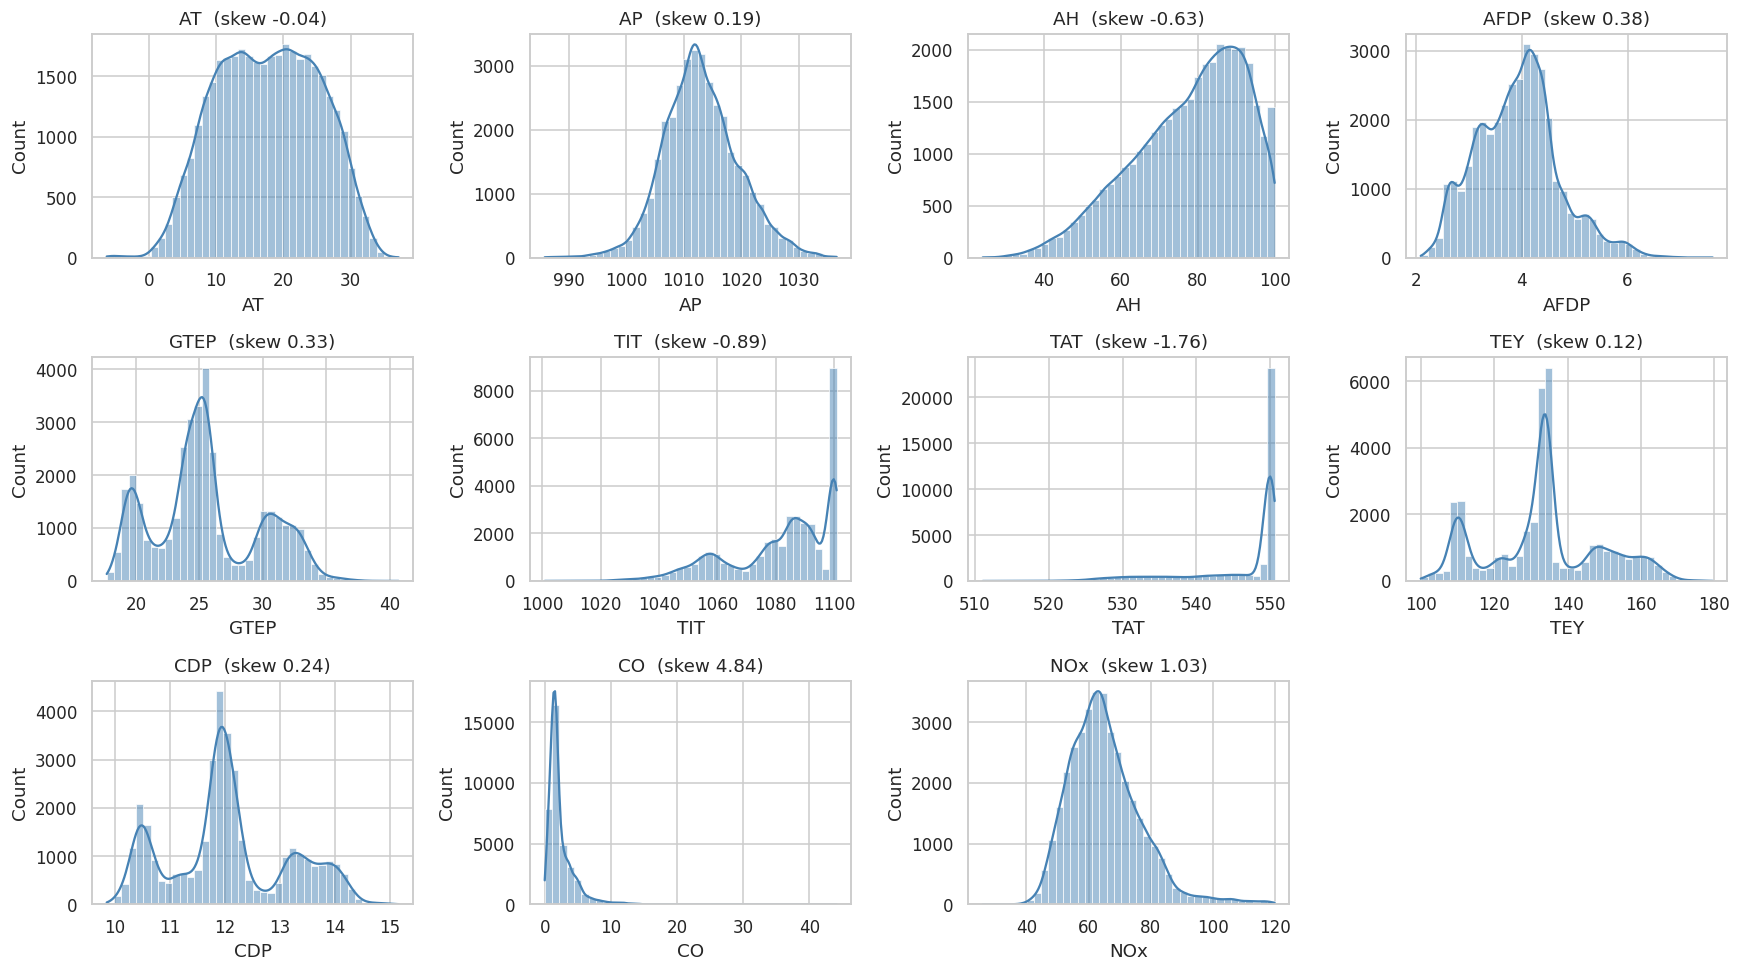

In [17]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, c in zip(axes.ravel(), NUM):
    sns.histplot(df[c], kde=True, bins=40, ax=ax, color="steelblue")
    ax.set_title(f"{c}  (skew {df[c].skew():.2f})")
axes.ravel()[-1].axis("off")
show("02_distributions")

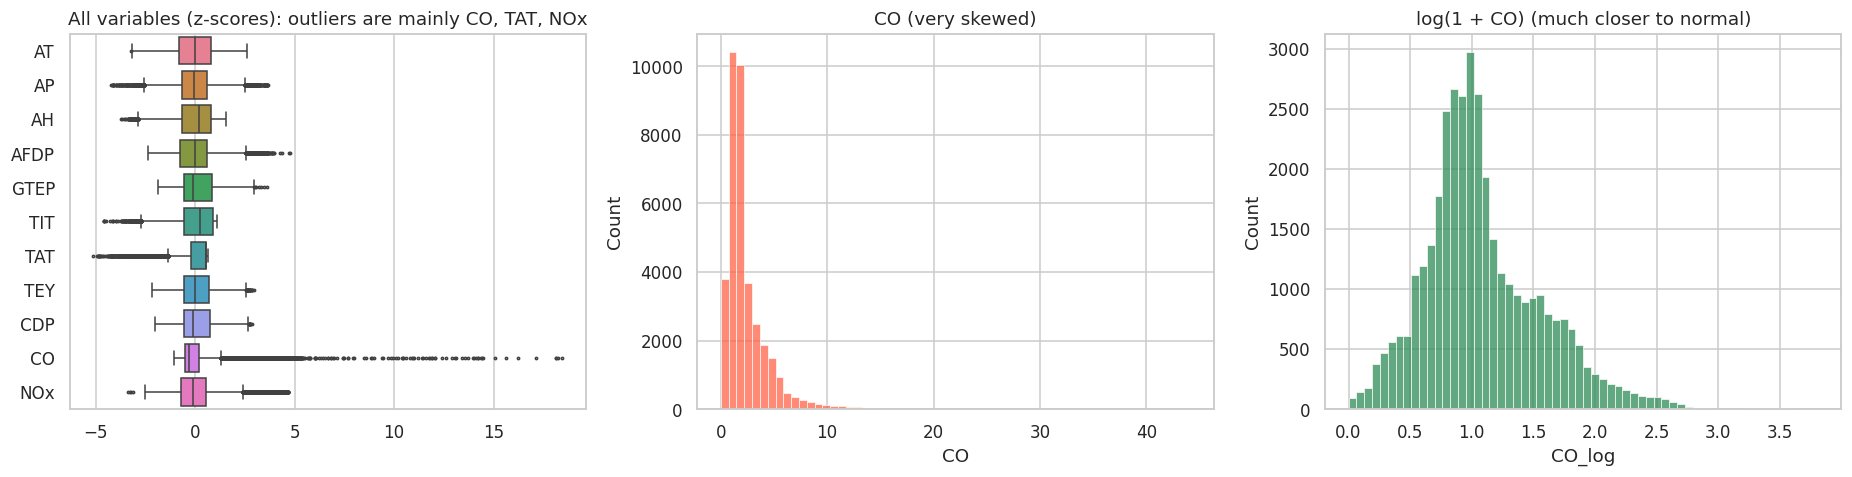

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=z, orient="h", ax=axes[0], fliersize=1.5)
axes[0].set_title("All variables (z-scores): outliers are mainly CO, TAT, NOx")
sns.histplot(df["CO"], bins=60, ax=axes[1], color="tomato"); axes[1].set_title("CO (very skewed)")
sns.histplot(df["CO_log"], bins=60, ax=axes[2], color="seagreen"); axes[2].set_title("log(1 + CO) (much closer to normal)")
show("03_boxplots_co_log")

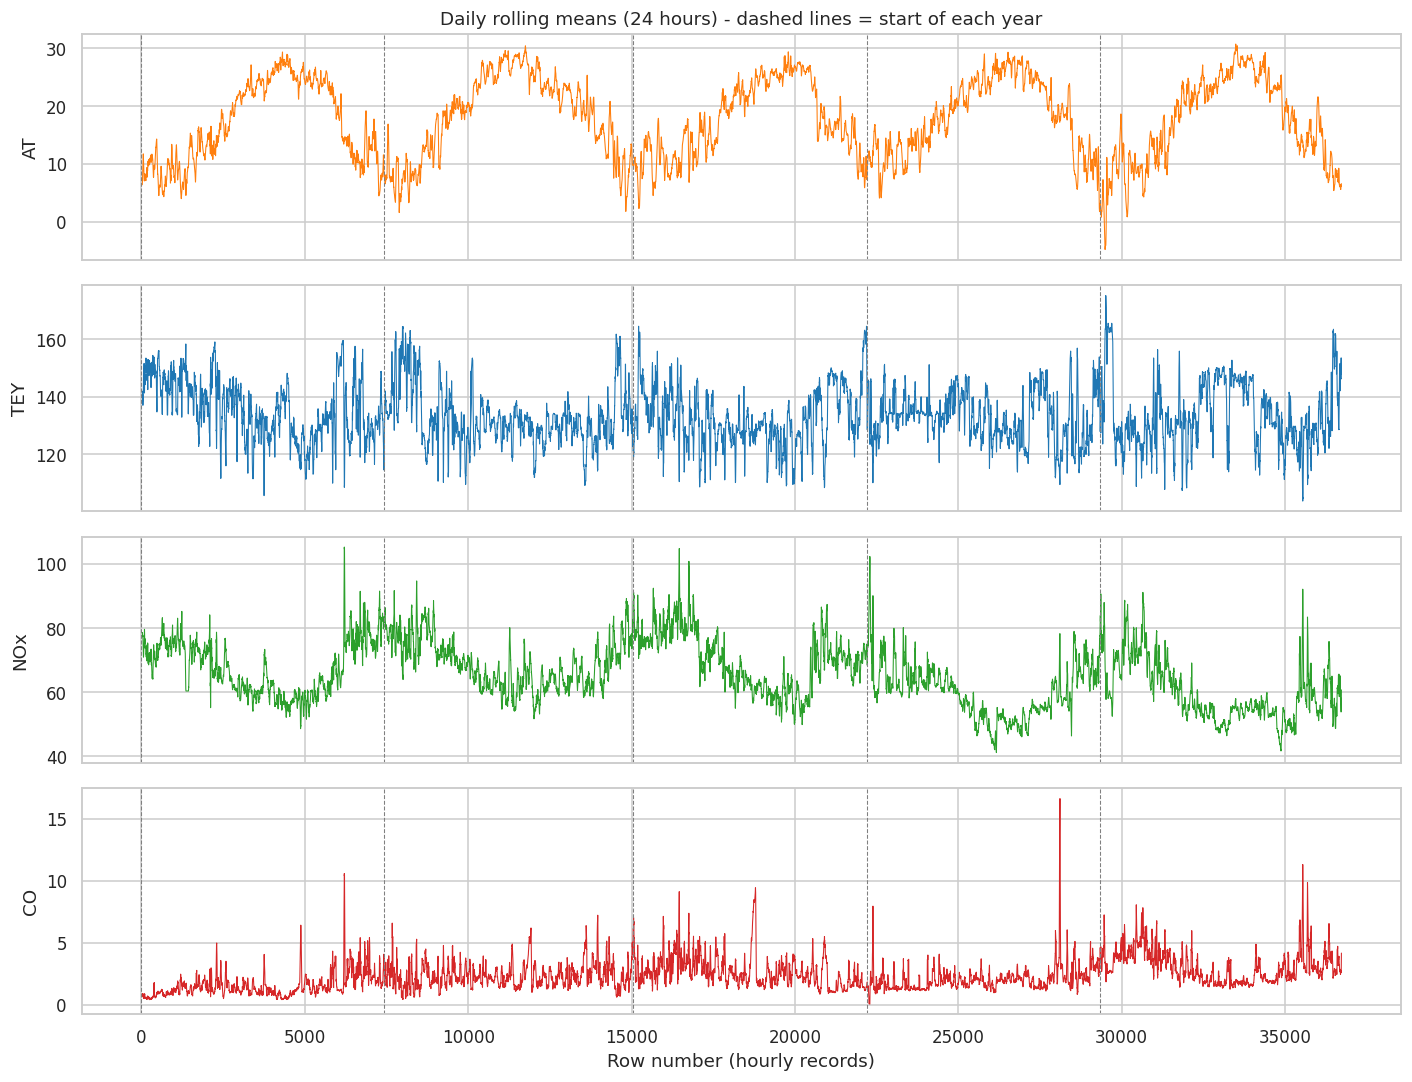

In [19]:
fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
for ax, (c, col) in zip(axes, [("AT", "tab:orange"), ("TEY", "tab:blue"), ("NOx", "tab:green"), ("CO", "tab:red")]):
    ax.plot(df[c].rolling(24).mean(), color=col, lw=0.7); ax.set_ylabel(c)
    for i in df.groupby("year").head(1).index: ax.axvline(i, color="grey", ls="--", lw=0.7)
axes[0].set_title("Daily rolling means (24 hours) - dashed lines = start of each year")
axes[-1].set_xlabel("Row number (hourly records)")
show("04_time_series")

,AT,TEY,TIT,AFDP,NOx,CO,CO_median
year,,,,,,,
2011,17.11,135.75,1084.73,4.09,67.58,1.57,1.16
2012,18.40,132.68,1082.89,4.31,68.79,2.36,1.64
2013,17.60,132.17,1081.57,3.70,70.01,2.72,1.78
2014,18.21,132.91,1078.83,3.91,60.08,2.08,1.66
2015,17.23,133.99,1078.97,3.60,59.89,3.13,2.53


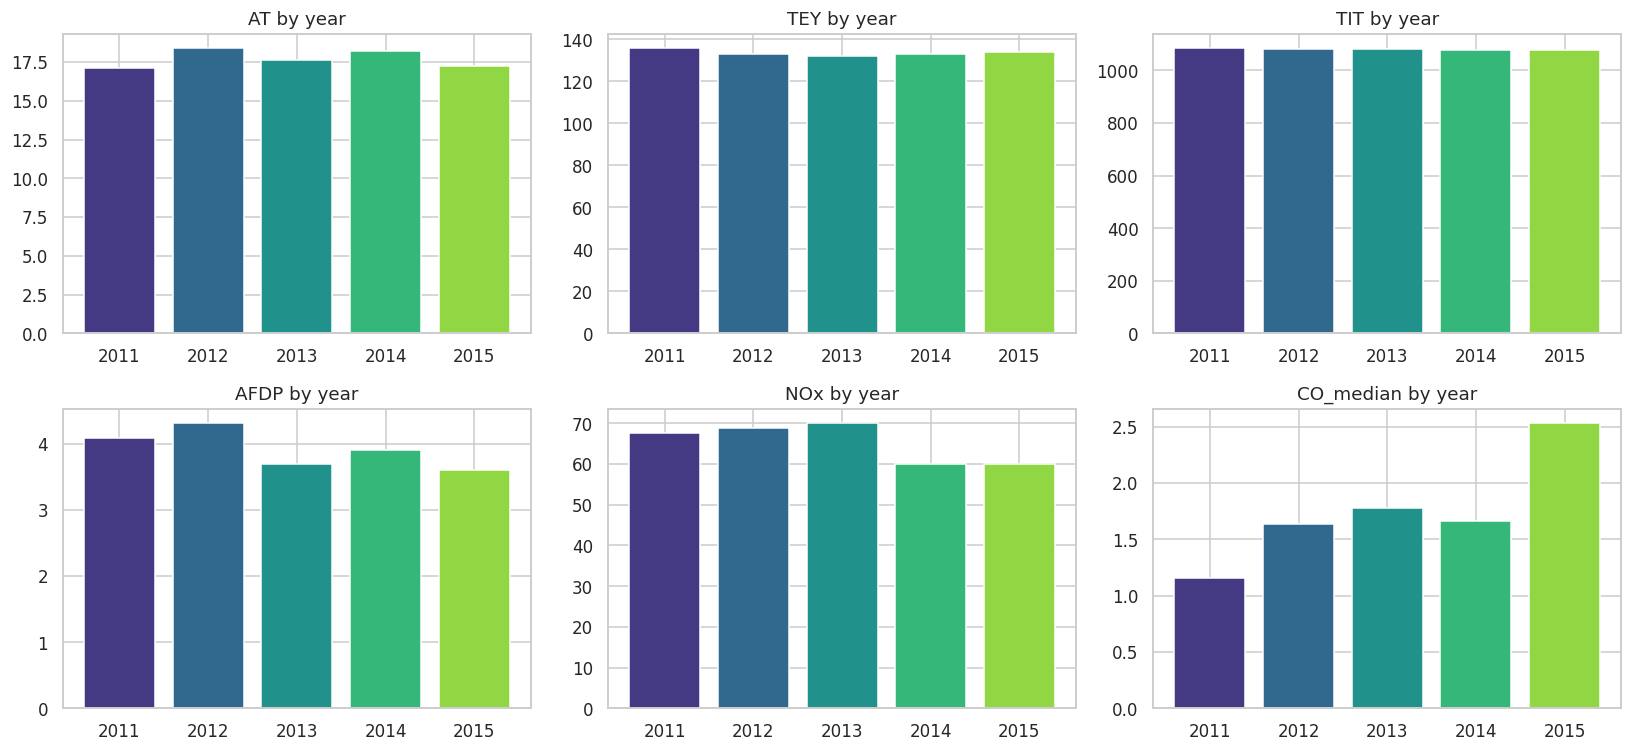

In [20]:
yearly = df.groupby("year")[["AT", "TEY", "TIT", "AFDP", "NOx", "CO"]].agg(["mean"]).droplevel(1, axis=1).round(2)
yearly["CO_median"] = df.groupby("year")["CO"].median().round(2)
display(yearly)
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), ["AT", "TEY", "TIT", "AFDP", "NOx", "CO_median"]):
    ax.bar(yearly.index.astype(str), yearly[c], color=sns.color_palette("viridis", 5)); ax.set_title(f"{c} by year")
show("05_yearly_summary")

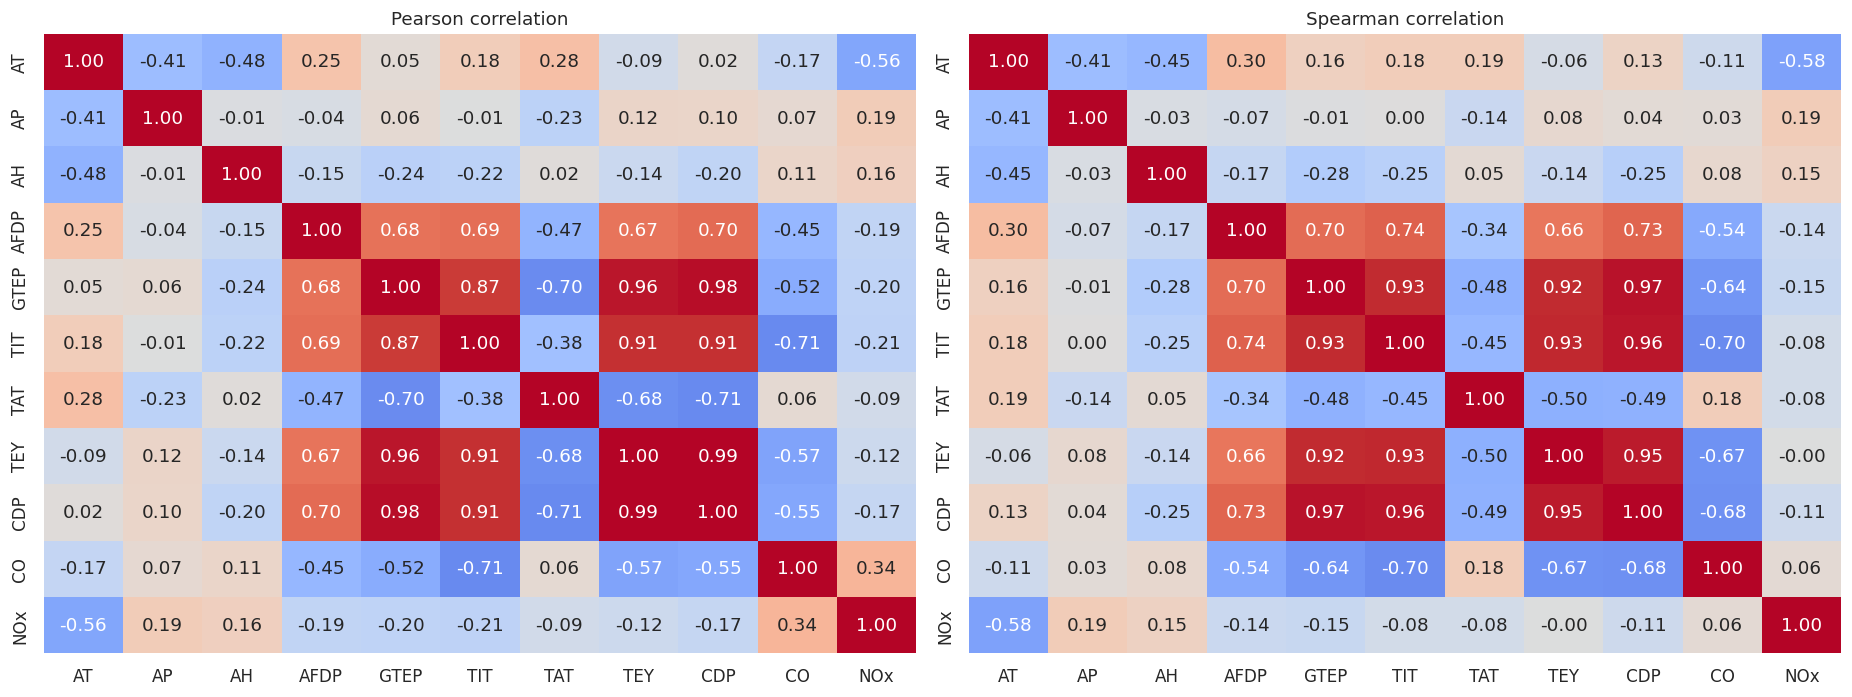


Strongest Pearson correlations with TEY:
CDP     0.99
GTEP    0.96
TIT     0.91
TAT    -0.68

Strongest Pearson correlations with NOx:
AT     -0.56
CO      0.34
TIT    -0.21
GTEP   -0.20

Strongest Pearson correlations with CO:
TIT    -0.71
TEY    -0.57
CDP    -0.55
GTEP   -0.52


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, m in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(df[NUM].corr(method=m), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, cbar=False)
    ax.set_title(f"{m.title()} correlation")
show("06_correlations")
for t in ["TEY", "NOx", "CO"]:
    print(f"\nStrongest Pearson correlations with {t}:")
    print(df[NUM].corr()[t].drop(t).sort_values(key=abs, ascending=False).head(4).round(2).to_string())

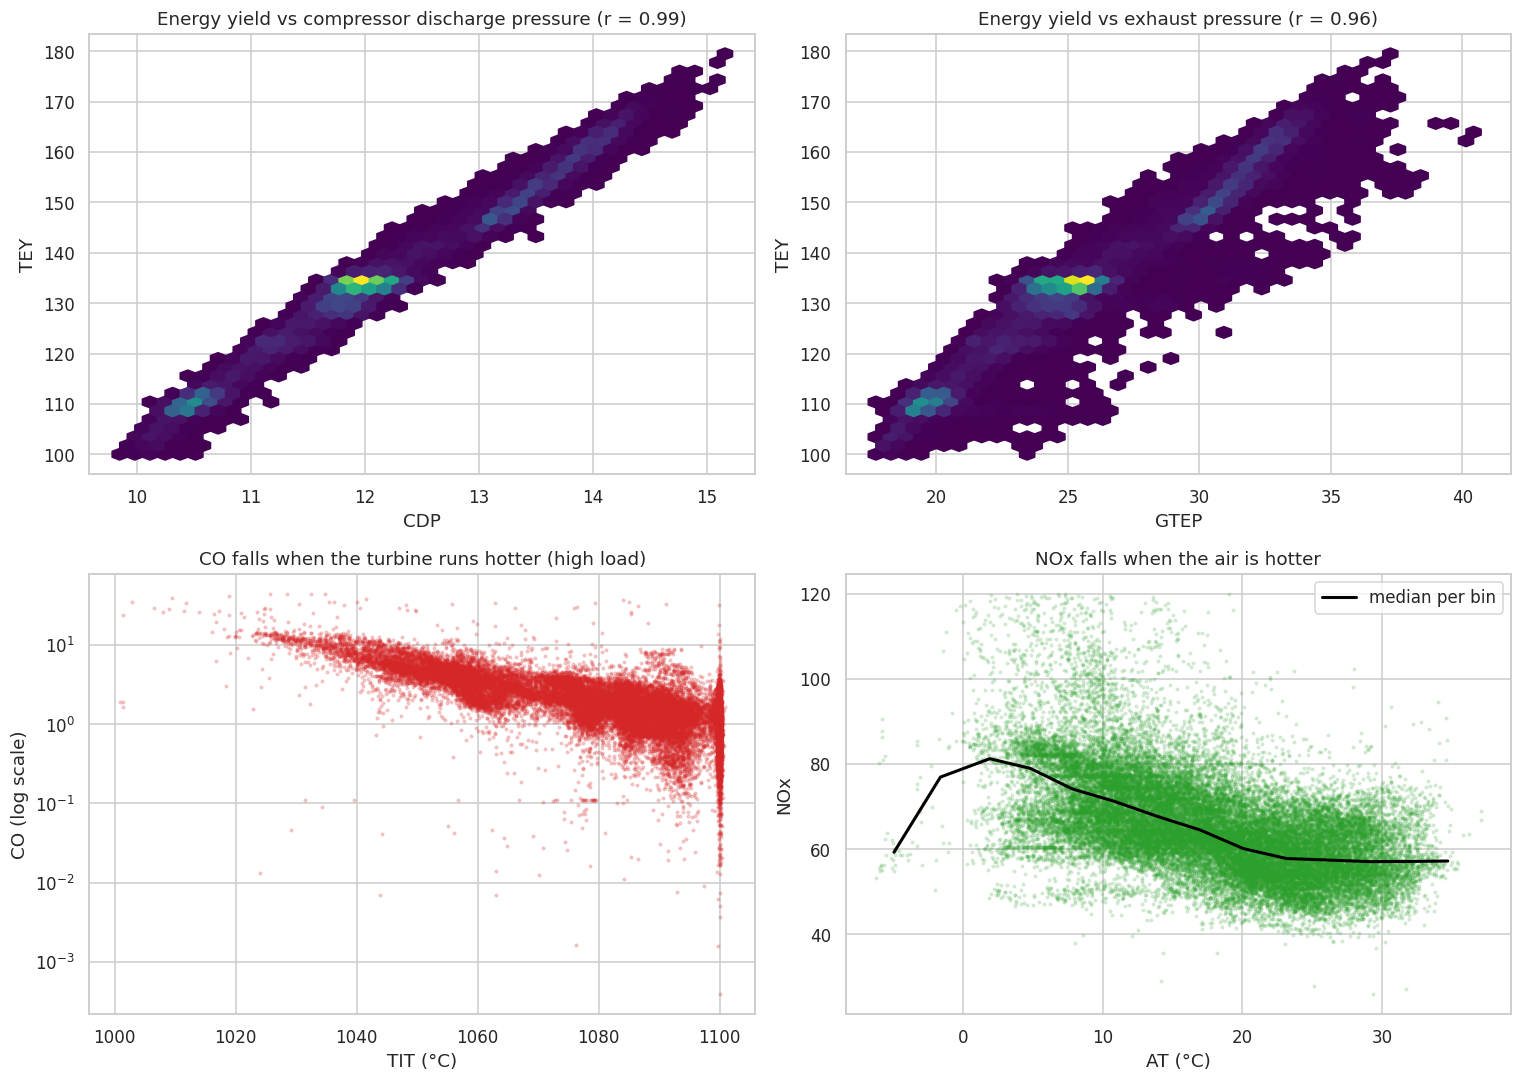

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].hexbin(df["CDP"], df["TEY"], gridsize=40, cmap="viridis", mincnt=1)
axes[0, 0].set(xlabel="CDP", ylabel="TEY", title="Energy yield vs compressor discharge pressure (r = %.2f)" % df["CDP"].corr(df["TEY"]))
axes[0, 1].hexbin(df["GTEP"], df["TEY"], gridsize=40, cmap="viridis", mincnt=1)
axes[0, 1].set(xlabel="GTEP", ylabel="TEY", title="Energy yield vs exhaust pressure (r = %.2f)" % df["GTEP"].corr(df["TEY"]))
axes[1, 0].scatter(df["TIT"], df["CO"], s=3, alpha=0.2, color="tab:red"); axes[1, 0].set_yscale("log")
axes[1, 0].set(xlabel="TIT (°C)", ylabel="CO (log scale)", title="CO falls when the turbine runs hotter (high load)")
axes[1, 1].scatter(df["AT"], df["NOx"], s=3, alpha=0.15, color="tab:green")
med = df.groupby(pd.cut(df["AT"], 14), observed=True).agg(AT=("AT", "mean"), NOx=("NOx", "median"))
axes[1, 1].plot(med["AT"], med["NOx"], color="black", lw=2, label="median per bin"); axes[1, 1].legend()
axes[1, 1].set(xlabel="AT (°C)", ylabel="NOx", title="NOx falls when the air is hotter")
show("07_key_relationships")

,TEY,TIT,CO,NOx
load_band,,,,
Low load,112.76,1059.6,3.55,61.05
Medium load,133.73,1086.8,1.49,66.02
High load,150.50,1099.9,1.26,62.50


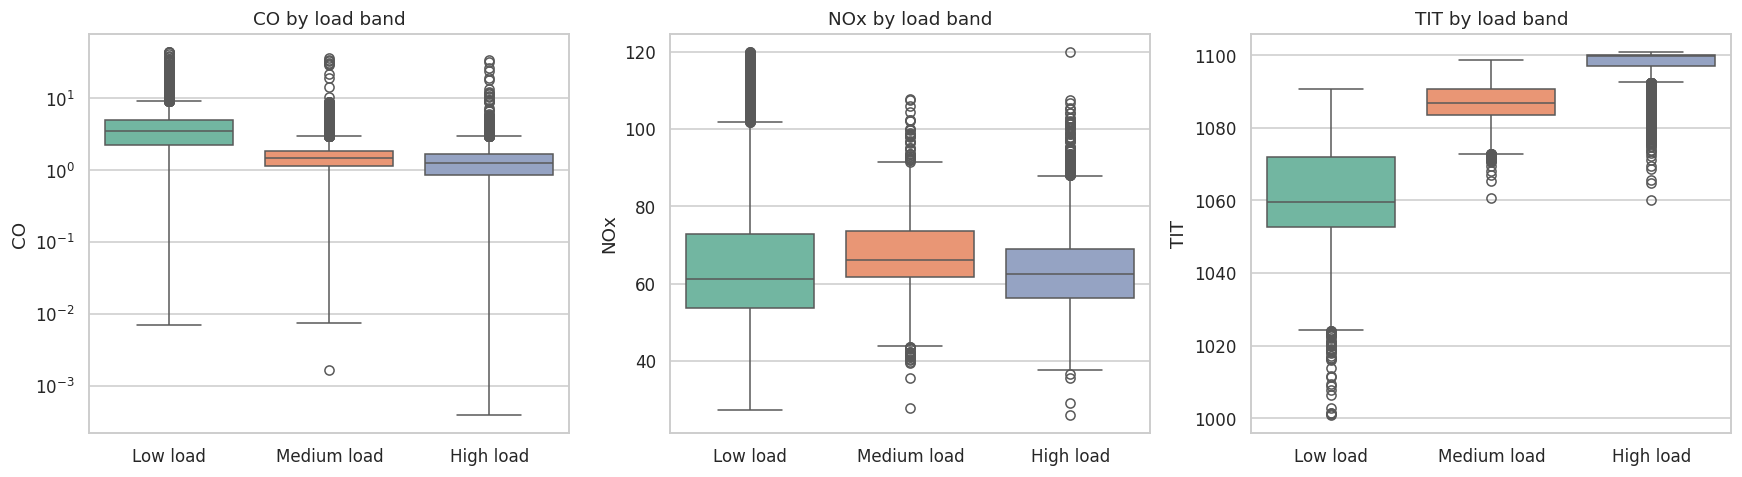

In [23]:
display(df.groupby("load_band", observed=True)[["TEY", "TIT", "CO", "NOx"]].median().round(2))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c in zip(axes, ["CO", "NOx", "TIT"]):
    sns.boxplot(data=df, x="load_band", y=c, ax=ax, palette="Set2")
    ax.set_title(f"{c} by load band"); ax.set_xlabel("")
axes[0].set_yscale("log")
show("08_load_bands")

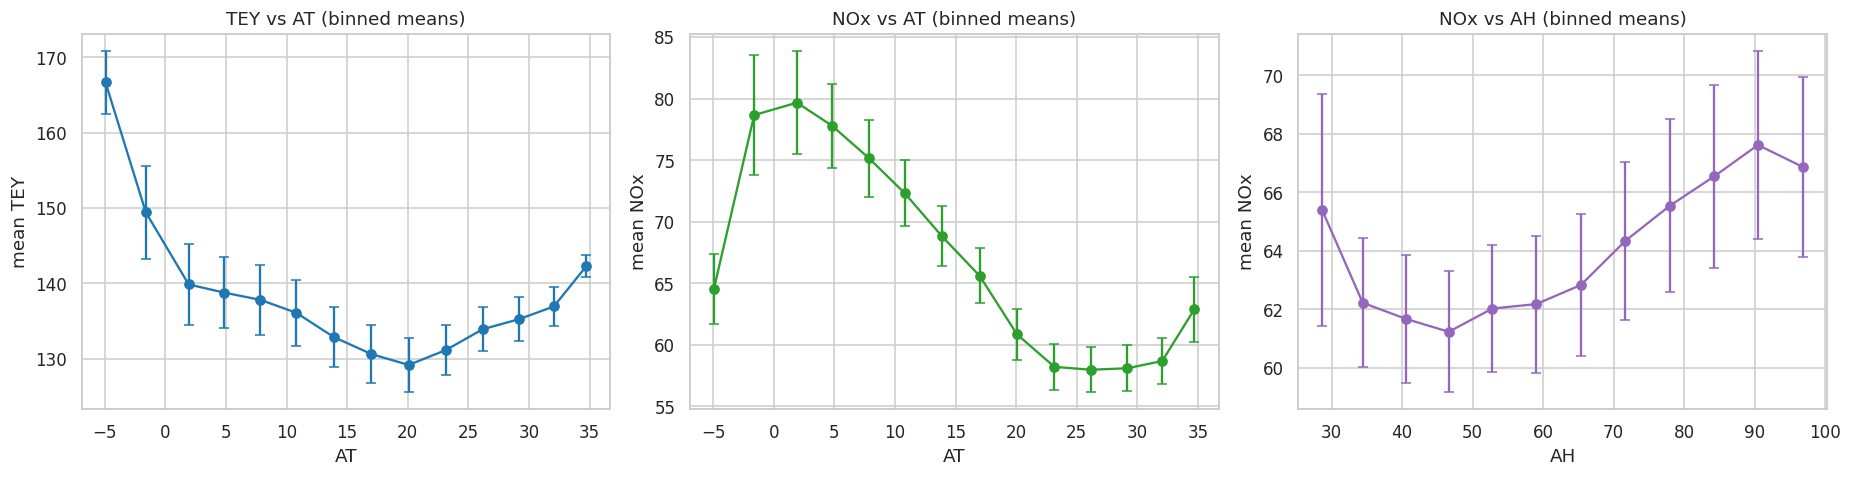

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (col, bins, tgt, colr) in zip(axes, [("AT", 14, "TEY", "tab:blue"), ("AT", 14, "NOx", "tab:green"), ("AH", 12, "NOx", "tab:purple")]):
    g = df.groupby(pd.cut(df[col], bins), observed=True).agg(x=(col, "mean"), y=(tgt, "mean"), sd=(tgt, "std"))
    ax.errorbar(g["x"], g["y"], yerr=g["sd"] / 4, marker="o", color=colr, capsize=3)
    ax.set(xlabel=col, ylabel=f"mean {tgt}", title=f"{tgt} vs {col} (binned means)")
show("09_ambient_effects")

In [25]:
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
sns.boxplot(data=df, x="year", y="AFDP", ax=axes[0],palette="virdis");axes[0].set_title("Air filter pressure drop by year")
g = df.groupby(pd.qcut(df["AFDP"],10),observed=True).agg(AFDP=("AFDP","mean"),TEY=("TEY","mean"))
axes[1].plot(g["AFDP"],g["TEY"],maeker="o",color="tab:blue")
axes[1].set(xlabel="AFDP (mean per decile"),ylabel ="mean TEY", title="Higher AFDP goas with higher load (not a cause)")
show("10_air_filter")
print("Spearman AFDP vs TEY: %.2f" % stats.spearmanr(df["AFDP"],df["TEY"])[0])

SyntaxError: unmatched ')' (1178344727.py, line 5)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x="year", y="AFDP", ax=axes[0], palette="viridis"); axes[0].set_title("Air filter pressure drop by year")
g = df.groupby(pd.qcut(df["AFDP"], 10), observed=True).agg(AFDP=("AFDP", "mean"), TEY=("TEY", "mean"))
axes[1].plot(g["AFDP"], g["TEY"], marker="o", color="tab:blue")
axes[1].set(xlabel="AFDP (mean per decile)", ylabel="mean TEY", title="Higher AFDP goes with higher load (not a cause)")
show("10_air_filter")
print("Spearman AFDP vs TEY: %.2f" % stats.spearmanr(df["AFDP"], df["TEY"])[0])

In [ ]:
groups =[g["NOx"].values for _, g in df.groupby("year")]
h,p=stats.kruskal(*groups)
print(f"NOx differs between years ?      Ksuskal_Wallis H = {h:.1f}, p={p:.2e}")
rho, p= stats.spearmanr(df["AT"],df["NOx"])
print(f"NOx vs ambient temperature:   Spearman rho = {rho:.2f}, p={p:.2e}")
lo=df.loc[df["load_band"]=="Low load","CO"]; hi=df.loc[df["load_band"]=="High load","CO"]
u,p =stats.mannwhitneyu(lo,hi)
print(f"CO low load vs hight load:    median{lo.median():.2f} vs {hi.median():.2f},Mann_Whitney p ={p:.2e}")
print("(A tiny p-value means the difference is real, not random. Always read it together with the size of the effect.)")

**Machine learning setup**

In [ ]:
AMBIENT = ["AT", "AP", "AH"]
TURBINE = ["AFDP", "GTEP", "TIT", "TAT", "CDP", "dT"]
TASKS = {                                        # name: (target, features, log-transform target?)
    "TEY (ambient only)": ("TEY", AMBIENT, False),
    "TEY (all sensors)":  ("TEY", AMBIENT + TURBINE, False),
    "NOx":                ("NOx", AMBIENT + TURBINE + ["TEY"], False),
    "CO":                 ("CO", AMBIENT + TURBINE + ["TEY"], True),
}
train = df[df["year"] <= 2013].reset_index(drop=True)     # 2011-2013 = training (same protocol as the dataset authors)
test = df[df["year"] >= 2014].reset_index(drop=True)      # 2014-2015 = unseen future
print("Train:", train.shape, "| Test:", test.shape)
# Distribution shift check: do the test years look like the training years?
display(pd.concat({"train": train[NUM].mean(), "test": test[NUM].mean()}, axis=1).assign(
    change_pct=lambda t: ((t["test"] / t["train"] - 1) * 100).round(1)).round(2))

def get_models():
    return {
        "Mean baseline": DummyRegressor(strategy="mean"),
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "Random Forest": RandomForestRegressor(n_estimators=120, max_depth=14, min_samples_leaf=3,
                                               n_jobs=-1, random_state=RANDOM_STATE),
        "Gradient Boosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08,
                                                           max_leaf_nodes=31, random_state=RANDOM_STATE),
    }

def wrap(model, log):
    return TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1) if log else model

def metrics(y, p):
    return {"RMSE": np.sqrt(mean_squared_error(y, p)), "MAE": mean_absolute_error(y, p),
            "MedAE": median_absolute_error(y, p), "R2": r2_score(y, p)}

In [ ]:
tscv = TimeSeriesSplit(n_splits=5)
scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}
cv_rows = []
for task, (target, feats, log) in TASKS.items():
    for name, model in get_models().items():
        r = cross_validate(wrap(model, log), train[feats], train[target], cv=tscv, scoring=scoring)
        cv_rows.append({"task": task, "model": name, "CV_RMSE": -r["test_rmse"].mean(),
                        "CV_RMSE_std": r["test_rmse"].std(), "CV_MAE": -r["test_mae"].mean(), "CV_R2": r["test_r2"].mean()})
cv_df = pd.DataFrame(cv_rows)
display(cv_df.round(3))

In [ ]:
fitted, preds, rows = {}, {}, []
for task, (target, feats, log) in TASKS.items():
    for name, model in get_models().items():
        m = wrap(model, log).fit(train[feats], train[target])
        p = m.predict(test[feats]); fitted[(task, name)] = m; preds[(task, name)] = p
        r = metrics(test[target], p)
        if target != "CO": r["MAPE_%"] = mean_absolute_percentage_error(test[target], p) * 100
        rows.append({"task": task, "model": name, **r})
res = pd.DataFrame(rows)
base_rmse = res[res["model"] == "Mean baseline"].set_index("task")["RMSE"]
res["RMSE_gain_vs_baseline_%"] = (1 - res["RMSE"] / res["task"].map(base_rmse)) * 100
res["beats_baseline"] = res["RMSE"] < res["task"].map(base_rmse)
display(res.round(3))
best = res[res["model"] != "Mean baseline"].sort_values("RMSE").groupby("task").head(1).set_index("task")["model"].to_dict()
print("\nBest model per task:")
for t, m in best.items():
    ok = bool(res[(res["task"] == t) & (res["model"] == m)]["beats_baseline"].iloc[0])
    print(f"  {t:20s} -> {m:18s}", "beats the mean baseline" if ok else "WARNING: no better than predicting the average!")

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, (task, (target, feats, log)) in zip(axes.ravel(), TASKS.items()):
    p = preds[(task, best[task])]; y = test[target].values
    idx = np.random.RandomState(0).choice(len(y), min(4000, len(y)), replace=False)
    ax.scatter(y[idx], p[idx], s=6, alpha=0.3)
    lim = [min(y.min(), p.min()), max(y.max(), p.max())]; ax.plot(lim, lim, "r--", lw=1.2, label="perfect")
    r = metrics(y, p); ax.set(xlabel=f"Actual {target}", ylabel=f"Predicted {target}",
                              title=f"{task} - {best[task]}\nR²={r['R2']:.3f}  RMSE={r['RMSE']:.2f}  MAE={r['MAE']:.2f}")
    ax.legend()
show("11_pred_vs_actual")

In [ ]:
def residual_plots(task):
    target = TASKS[task][0]; y = test[target].values; p = preds[(task, best[task])]; resid = y - p
    fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
    axes[0].scatter(p, resid, s=4, alpha=0.25); axes[0].axhline(0, color="r"); axes[0].set(xlabel="Predicted", ylabel="Residual", title="Residuals vs predicted")
    sns.histplot(resid, bins=50, kde=True, ax=axes[1], color="seagreen"); axes[1].set_title("Residual distribution")
    stats.probplot(resid, dist="norm", plot=axes[2]); axes[2].set_title("Q-Q plot (normal?)")
    axes[3].plot(pd.Series(resid).rolling(168).mean(), color="tab:purple"); axes[3].axhline(0, color="r")
    axes[3].set(xlabel="Test row", title="Residuals over time (weekly mean)")
    dw = np.sum(np.diff(resid) ** 2) / np.sum(resid ** 2)
    fig.suptitle(f"{task} - {best[task]} | mean residual = {resid.mean():.3f} | Durbin-Watson = {dw:.2f} (2 = no autocorrelation)", y=1.04)
    show(f"12_residuals_{task.split()[0].lower()}_{'ambient' if 'ambient' in task else 'main'}")

for t in TASKS: residual_plots(t)

In [ ]:
seg = pd.DataFrame({"year": test["year"], "load_band": test["load_band"], "AT_band": test["AT_band"]})
tables = {k: {} for k in ["year", "load_band", "AT_band"]}
for task, (target, feats, log) in TASKS.items():
    ae = pd.Series(np.abs(test[target].values - preds[(task, best[task])]))
    rel = ae / test[target].abs().mean() * 100                      # error as % of the average value
    for k in tables: tables[k][task] = rel.groupby(seg[k].values).mean()
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for ax, k in zip(axes, tables):
    sns.heatmap(pd.DataFrame(tables[k]).T, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax, cbar=False)
    ax.set_title(f"Mean absolute error (% of mean target) by {k}"); ax.set_xlabel("")
show("13_error_by_segment")

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (task, (target, feats, log)) in zip(axes.ravel(), TASKS.items()):
    sample = test.sample(3000, random_state=RANDOM_STATE)
    pi = permutation_importance(fitted[(task, best[task])], sample[feats], sample[target], n_repeats=5,
                                scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE)
    s = pd.Series(pi.importances_mean, index=feats).sort_values()
    ax.barh(s.index, s.values, color="steelblue"); ax.set_title(f"{task}: RMSE increase when a feature is shuffled")
show("14_feature_importance")

In [ ]:
target, feats, _ = TASKS["NOx"]
search = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    {"learning_rate": [0.03, 0.05, 0.08, 0.1], "max_iter": [200, 400, 600], "max_leaf_nodes": [15, 31, 63],
     "min_samples_leaf": [20, 50, 100], "l2_regularization": [0, 0.1, 1, 10]},
    n_iter=12, cv=TimeSeriesSplit(n_splits=3), scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE, n_jobs=-1).fit(train[feats], train[target])
tuned = search.best_estimator_
print("Best parameters:", search.best_params_)
before = metrics(test[target], preds[("NOx", "Gradient Boosting")]); after = metrics(test[target], tuned.predict(test[feats]))
display(pd.DataFrame({"before tuning": before, "after tuning": after}).round(3))
print("Tuning does not help: the problem is not the model settings, it is DRIFT (NOx dropped ~10 mg/m3 from 2014).")

In [ ]:
WINDOW, STEP = 7000, 500
start = int(np.flatnonzero(df["year"].values >= 2014)[0])          # first row of the test period

def walk_forward(target, feats, log=False):
    inv = np.expm1 if log else (lambda v: v)
    out = {"y": [], "pred": [], "lo": [], "hi": []}
    for s in range(start, len(df), STEP):
        tr, te = df.iloc[max(0, s - WINDOW):s], df.iloc[s:s + STEP]
        yt = np.log1p(tr[target]) if log else tr[target]
        kw = dict(learning_rate=0.08, random_state=RANDOM_STATE)
        mid = HistGradientBoostingRegressor(max_iter=200, **kw).fit(tr[feats], yt)
        lo_m = HistGradientBoostingRegressor(loss="quantile", quantile=0.05, max_iter=120, **kw).fit(tr[feats], yt)
        hi_m = HistGradientBoostingRegressor(loss="quantile", quantile=0.95, max_iter=120, **kw).fit(tr[feats], yt)
        lo_p, hi_p = inv(lo_m.predict(te[feats])), inv(hi_m.predict(te[feats]))
        out["y"].append(te[target].values); out["pred"].append(inv(mid.predict(te[feats])))
        out["lo"].append(np.minimum(lo_p, hi_p)); out["hi"].append(np.maximum(lo_p, hi_p))
    return {k: np.concatenate(v) for k, v in out.items()}

wf = {t: walk_forward(TASKS[t][0], TASKS[t][1], TASKS[t][2]) for t in ["NOx", "CO"]}
rows = []
for t in wf:
    rows.append({"task": t, "approach": f"static ({best[t]}, trained once on 2011-13)", **metrics(test[TASKS[t][0]], preds[(t, best[t])])})
    rows.append({"task": t, "approach": "walk-forward Gradient Boosting", **metrics(wf[t]["y"], wf[t]["pred"])})
wf_res = pd.DataFrame(rows); display(wf_res.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, t in zip(axes, wf):
    y = wf[t]["y"]
    ax.plot(pd.Series(np.abs(y - preds[(t, best[t])])).rolling(168).mean(), label="static model", color="tab:red")
    ax.plot(pd.Series(np.abs(y - wf[t]["pred"])).rolling(168).mean(), label="walk-forward", color="tab:green")
    ax.set(title=f"{t}: absolute error (weekly mean)", xlabel="Test hour"); ax.legend()
show("16_static_vs_walkforward")

In [ ]:
for t in wf:
    cov = np.mean((wf[t]["y"] >= wf[t]["lo"]) & (wf[t]["y"] <= wf[t]["hi"])) * 100
    print(f"{t}: 90% interval covers {cov:.1f}% of the actual values | average width {np.mean(wf[t]['hi'] - wf[t]['lo']):.2f}")
n = 500
fig, ax = plt.subplots(figsize=(13, 4))
ax.fill_between(range(n), wf["NOx"]["lo"][:n], wf["NOx"]["hi"][:n], alpha=0.3, color="tab:blue", label="90% prediction interval")
ax.plot(wf["NOx"]["y"][:n], color="black", lw=0.8, label="actual NOx"); ax.plot(wf["NOx"]["pred"][:n], color="tab:red", lw=0.8, label="predicted")
ax.set(xlabel="First 500 test hours", ylabel="NOx (mg/m3)", title="NOx: walk-forward prediction with uncertainty band"); ax.legend()
show("17_prediction_interval")

In [ ]:
import joblib
summary = res[res["model"] != "Mean baseline"].sort_values(["task", "RMSE"]).groupby("task").head(1)
display(summary.round(3))
display(wf_res.round(3))
df.drop(columns=["pos_in_year"]).to_csv(f"{OUT}/gt_clean.csv", index=False)
joblib.dump({t: fitted[(t, best[t])] for t in TASKS}, f"{OUT}/best_models.joblib")
print("Saved: cleaned data, best models and all charts in the folder:", OUT)